# Практична робота №16
## Кореляційний аналіз: Пірсон, Спірмен і кореляційна матриця

**Студент:** Панасюк Дмитро  
**Номер за списком:** 15  
**Варіант:** №5 — **Дніпро**  
**Тема даних:** температура повітря, опалювальні дні та витрати на опалення за 12 місяців.

**Мета:** дослідити напрямок і силу зв'язку між змінними, перевірити статистичну значущість кореляцій, побудувати кореляційні матриці та показати вплив аномального спостереження.

*Дані синтетичні, створені за формулою, наведеною в умові завдання, з `np.random.seed(5)`; усі суми витрат наведені в умовних тисячах гривень.*

## Підготовка вихідних даних

Використаємо температури **Дніпра** з таблиці варіантів: `[-4, -3, 3, 11, 17, 21, 23, 22, 16, 9, 3, -2]` °C. Відтворимо процедуру генерації з методичних вказівок без зміни формул і порядку викликів випадкового генератора.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import pearsonr, spearmanr

plt.rcParams.update({"font.family": "DejaVu Sans", "axes.grid": True, "grid.alpha": 0.18, "figure.dpi": 110})

np.random.seed(5)  # номер варіанта, для повної відтворюваності
city = "Дніпро"
monthly_temp = [-4, -3, 3, 11, 17, 21, 23, 22, 16, 9, 3, -2]
months = ["Січ", "Лют", "Бер", "Кві", "Тра", "Чер",
          "Лип", "Сер", "Вер", "Жов", "Лис", "Гру"]

rows = []
for month, temp in zip(months, monthly_temp):
    heating_days = np.clip(18 - temp + np.random.normal(0, 1.5), 0, 30)
    heating_days = round(heating_days)
    cost = 0.15 * heating_days + np.random.normal(0, 1.0)
    cost = round(max(cost, 0), 1)
    rows.append({
        "місто": city,
        "місяць": month,
        "температура": temp,
        "опалювальні_дні": heating_days,
        "витрати_на_опалення": cost,
    })

climate = pd.DataFrame(rows)
assert climate.shape == (12, 5)
print("Розмір таблиці:", climate.shape)
display(climate)

Розмір таблиці: (12, 5)


,місто,місяць,температура,опалювальні_дні,витрати_на_опалення
0,Дніпро,Січ,-4,23,3.1
1,Дніпро,Лют,-3,25,3.5
2,Дніпро,Бер,3,15,3.8
3,Дніпро,Кві,11,6,0.3
4,Дніпро,Тра,17,1,0.0
5,Дніпро,Чер,21,0,0.0
6,Дніпро,Лип,23,0,0.6
7,Дніпро,Сер,22,0,0.0
8,Дніпро,Вер,16,4,2.5
9,Дніпро,Жов,9,7,1.7


## Завдання 1. Діаграма розсіювання

Побудуємо залежність умовних витрат на опалення (**Y**) від середньомісячної температури (**X**), використовуючи об'єктний інтерфейс Matplotlib.

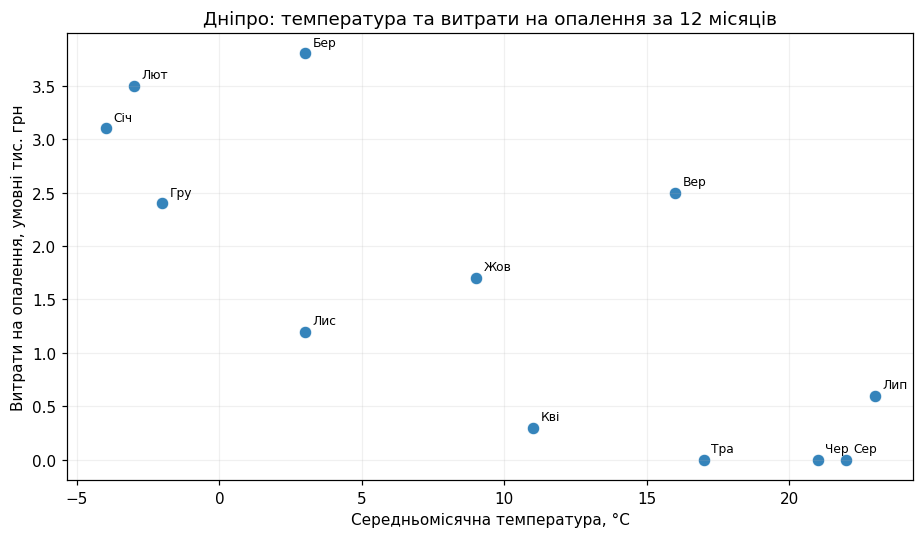

In [2]:
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.scatter(climate["температура"], climate["витрати_на_опалення"],
           s=68, alpha=0.9, edgecolors="white", linewidths=0.7)
for _, row in climate.iterrows():
    ax.annotate(row["місяць"], (row["температура"], row["витрати_на_опалення"]),
                xytext=(5, 5), textcoords="offset points", fontsize=8)
ax.set_xlabel("Середньомісячна температура, °C")
ax.set_ylabel("Витрати на опалення, умовні тис. грн")
ax.set_title("Дніпро: температура та витрати на опалення за 12 місяців")
fig.tight_layout()
plt.show()

**Опис графіка.** Хмара точок має переважно **спадний (негативний)** напрямок: при нижчій температурі витрати зазвичай вищі. Зв'язок приблизно лінійний, проте з розкидом і вирівнюванням поблизу нульових витрат у теплі місяці (через обрізання витрат знизу на 0 у формулі). Очевидного поодинокого надзвичайного викиду в початкових даних немає. Це узгоджується з генерацією: температура впливає на кількість опалювальних днів, а та — на витрати; доданий шум не робить залежність ідеальною.

## Завдання 2. Коефіцієнти Пірсона й Спірмена, p-value та 95% ДІ

Перевіримо двобічні гіпотези при **α = 0,05**:

- **H₀:** у генеральній сукупності кореляція дорівнює нулю (для кожного методу у його власному сенсі).
- **H₁:** кореляція відмінна від нуля.

Пірсон оцінює силу **лінійного** зв'язку за числовими значеннями; Спірмен — силу **монотонного** зв'язку за рангами.

In [3]:
x = climate["температура"]
y = climate["витрати_на_опалення"]

pearson_result = pearsonr(x, y)
spearman_result = spearmanr(x, y)
pearson_ci = pearson_result.confidence_interval(confidence_level=0.95)
alpha = 0.05

print(f"Пірсон: r = {pearson_result.statistic:.6f}; p-value = {pearson_result.pvalue:.8f}")
print(f"Спірмен: rho = {spearman_result.statistic:.6f}; p-value = {spearman_result.pvalue:.8f}")
print(f"95% довірчий інтервал для r: [{pearson_ci.low:.6f}; {pearson_ci.high:.6f}]")
print("Рішення, Пірсон:", "відхиляємо H₀" if pearson_result.pvalue < alpha else "не відхиляємо H₀")
print("Рішення, Спірмен:", "відхиляємо H₀" if spearman_result.pvalue < alpha else "не відхиляємо H₀")

Пірсон: r = -0.781396; p-value = 0.00268775
Спірмен: rho = -0.761915; p-value = 0.00397495
95% довірчий інтервал для r: [-0.935692; -0.376199]
Рішення, Пірсон: відхиляємо H₀
Рішення, Спірмен: відхиляємо H₀


**Висновок.** Пірсон: **r = -0.7814**, **p = 0.00269**; Спірмен: **ρ = -0.7619**, **p = 0.00397**. Обидва p-value менші за 0,05, тому **відхиляємо H₀ в обох перевірках**. Маємо сильний негативний зв'язок у згенерованих даних.

Модулі коефіцієнтів відрізняються лише приблизно на **0.0195**, тобто результати близькі: залежність здебільшого спадна і приблизно лінійна. Невелика різниця пов'язана з випадковим шумом, однаковими/нульовими витратами та переходом від вихідних значень до рангів.

**95% довірчий інтервал Пірсона:** **[-0.9357; -0.3762]**. Він повністю нижче 0, що узгоджується з тестом. Його коректна частотна інтерпретація: якби багаторазово отримувати аналогічні вибірки та будувати інтервали цим методом за відповідних припущень, приблизно 95% таких інтервалів містили б істинну генеральну кореляцію. Це **не** 95%-ва ймовірність істинної кореляції для вже отриманого конкретного інтервалу.

*Обмеження:* 12 місяців одного синтетичного року — мала сезонна серія, тому формальні p-value і довірчий інтервал слід розуміти у межах припущень тестів, а не як надійні кліматологічні висновки.

## Завдання 3. Кореляційна матриця трьох змінних

Розрахуємо матрицю **3×3** для Пірсона через `.corr()` (за замовчуванням) та для Спірмена через `.corr(method="spearman")`. У діагоналі обох матриць — кореляція змінної із самою собою, тобто 1.

In [4]:
numeric_cols = ["температура", "опалювальні_дні", "витрати_на_опалення"]
numeric_data = climate[numeric_cols]
corr_pearson = numeric_data.corr()
corr_spearman = numeric_data.corr(method="spearman")

print("Матриця Пірсона:")
display(corr_pearson.round(4))
print("Матриця Спірмена:")
display(corr_spearman.round(4))

Матриця Пірсона:


,температура,опалювальні_дні,витрати_на_опалення
температура,1.0000,-0.9737,-0.7814
опалювальні_дні,-0.9737,1.0000,0.8183
витрати_на_опалення,-0.7814,0.8183,1.0000


Матриця Спірмена:


,температура,опалювальні_дні,витрати_на_опалення
температура,1.0000,-0.9841,-0.7619
опалювальні_дні,-0.9841,1.0000,0.8156
витрати_на_опалення,-0.7619,0.8156,1.0000


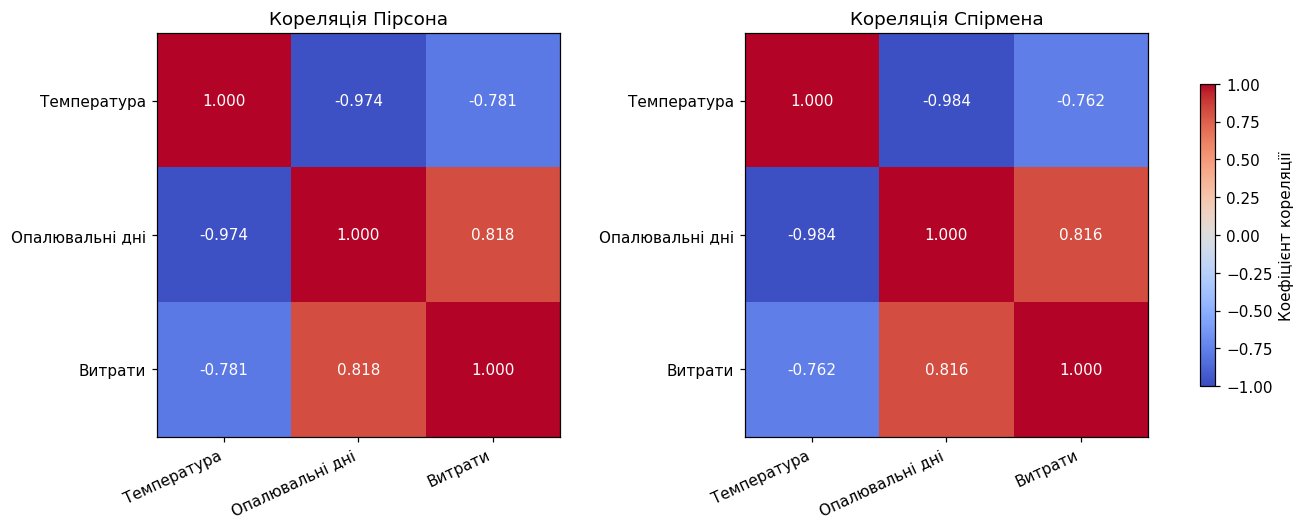

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7), constrained_layout=True)
short_labels = ["Температура", "Опалювальні дні", "Витрати"]
for ax, matrix, title in zip(axes, [corr_pearson, corr_spearman],
                              ["Кореляція Пірсона", "Кореляція Спірмена"]):
    im = ax.imshow(matrix.to_numpy(), vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(3), short_labels, rotation=25, ha="right")
    ax.set_yticks(range(3), short_labels)
    ax.set_title(title)
    ax.grid(False)
    for i in range(3):
        for j in range(3):
            color = "white" if abs(matrix.iloc[i, j]) > 0.65 else "black"
            ax.text(j, i, f"{matrix.iloc[i, j]:.3f}",
                    ha="center", va="center", fontsize=10, color=color)
fig.colorbar(im, ax=axes, shrink=0.75, label="Коефіцієнт кореляції")
plt.show()

**Інтерпретація.** За модулем найсильніше корелюють **температура і кількість опалювальних днів**: Пірсон **-0.9737**, Спірмен **-0.9841**. Найслабший серед трьох зв'язків — **температура й витрати на опалення**: Пірсон **-0.7814**, Спірмен **-0.7619**. Між опалювальними днями й витратами — позитивний зв'язок (**0.8183** за Пірсоном).

Це очікувано: опалювальні дні майже напряму отримані з температури, тоді як до витрат додано **окремий випадковий шум**, що послаблює їхню кореляцію з температурою. При переході до Спірмена **напрямки зв'язків і порядок за силою не змінюються**.

## Завдання 4. Кореляція і причинність

У цьому **синтетичному** наборі температура не просто пов'язана з витратами статистично: формула спочатку обчислює `опалювальні_дні` як функцію температури з шумом, а потім `витрати_на_опалення = 0.15 × опалювальні_дні + шум` (із нижньою межею 0). Отже, у **моделі генерації** закладено спрямований, переважно опосередкований через кількість днів вплив температури на витрати. На відміну від прикладу «морозиво й утоплення», де спільна причина — спекотна погода, у нашому коді додаткова спільна прихована причина не потрібна для отримання кореляції: її створює сам ланцюжок формул. Однак у реальному світі витрати можуть залежати ще й від тарифів, утеплення, площі будинку, економії тощо, тому за однією лише кореляцією реальний причинний ефект не встановити. Таким чином, **причинний механізм тут відомий із коду моделі**, а не доведений самим значенням r.

## Завдання 5. Вплив аномального спостереження на кореляцію

Додамо **один новий аномальний рядок** на основі вересневого спостереження: через умовну аварію котельні витрати збільшились **у 5 разів**, хоча температура й опалювальні дні не змінилися. Вихідний `climate` збережемо без змін. Отже, це навмисний сценарій із 13 спостереженнями, а не виправлення реальних даних.

In [6]:
anomaly = climate.loc[climate["місяць"] == "Вер"].iloc[0].copy()
anomaly["місяць"] = "Вер (аварія)"
anomaly["витрати_на_опалення"] = round(float(anomaly["витрати_на_опалення"]) * 5, 1)
climate_anomaly = pd.concat([climate, pd.DataFrame([anomaly])], ignore_index=True)

new_pearson = pearsonr(climate_anomaly["температура"],
                       climate_anomaly["витрати_на_опалення"])
new_spearman = spearmanr(climate_anomaly["температура"],
                         climate_anomaly["витрати_на_опалення"])

comparison = pd.DataFrame({
    "коефіцієнт": ["Пірсон (r)", "Спірмен (ρ)"],
    "до_аномалії": [pearson_result.statistic, spearman_result.statistic],
    "після_аномалії": [new_pearson.statistic, new_spearman.statistic],
    "абсолютна_зміна": [abs(new_pearson.statistic - pearson_result.statistic),
                         abs(new_spearman.statistic - spearman_result.statistic)],
    "p_після": [new_pearson.pvalue, new_spearman.pvalue],
})
print("Додане аномальне спостереження:")
display(pd.DataFrame([anomaly]))
print("Порівняння кореляцій:")
display(comparison.round(6))
print("Початкова таблиця залишилася без змін:", climate.shape)
print("Таблиця з аномалією:", climate_anomaly.shape)

Додане аномальне спостереження:


,місто,місяць,температура,опалювальні_дні,витрати_на_опалення
8,Дніпро,Вер (аварія),16,4,12.5


Порівняння кореляцій:


,коефіцієнт,до_аномалії,після_аномалії,абсолютна_зміна,p_після
0,Пірсон (r),-0.781396,-0.155742,0.625654,0.611401
1,Спірмен (ρ),-0.761915,-0.620501,0.141414,0.023648


Початкова таблиця залишилася без змін: (12, 5)
Таблиця з аномалією: (13, 5)


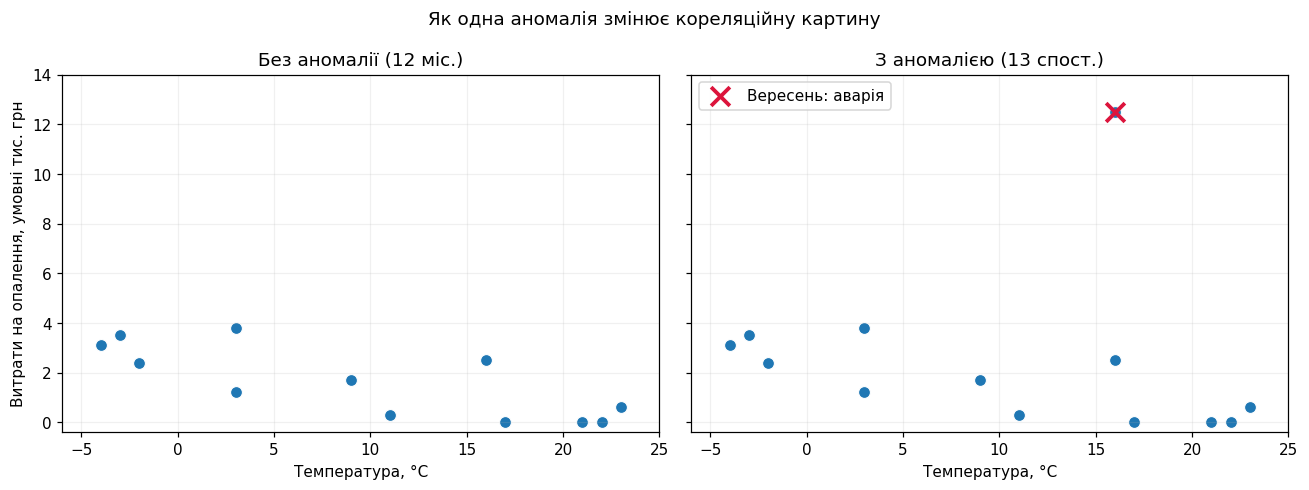

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)
for ax, df, title in [(axes[0], climate, "Без аномалії (12 міс.)"),
                       (axes[1], climate_anomaly, "З аномалією (13 спост.)")]:
    ax.scatter(df["температура"], df["витрати_на_опалення"],
               s=60, edgecolors="white", linewidths=0.7)
    ax.set_title(title)
    ax.set_xlabel("Температура, °C")
    ax.set_xlim(-6, 25)
    ax.set_ylim(-0.4, 14)
axes[0].set_ylabel("Витрати на опалення, умовні тис. грн")
axes[1].scatter([anomaly["температура"]], [anomaly["витрати_на_опалення"]],
                marker="x", s=150, color="crimson", linewidths=2.5, label="Вересень: аварія")
axes[1].legend(loc="upper left")
fig.suptitle("Як одна аномалія змінює кореляційну картину")
fig.tight_layout()
plt.show()

**Результат.** До додавання аномалії: **r = -0.7814**, **ρ = -0.7619**. Після додавання: **r = -0.1557**, **ρ = -0.6205**. Абсолютна зміна коефіцієнта Пірсона — **0.6257**, Спірмена — **0.1414**. Отже, **Пірсон змінився набагато сильніше**.

Пояснення: Пірсон використовує вихідні числові величини та коваріацію, тому одна дуже велика сума суттєво впливає на нього. Спірмен порівнює **ранги**: збільшення витрат у багато разів змінює позицію спостереження в порядку, але не додає пропорційно великої ваги самій величині стрибка. Спірмен не є повністю нечутливим до викидів, однак **у цьому прикладі** значно стійкіший.

## Відповіді на контрольні питання

**1. Чому Пірсон ділить на добуток стандартних відхилень і чому r ∈ [−1; 1]?**  
Коваріація залежить від одиниць вимірювання обох змінних; ділення на `sₓ × sᵧ` нормує її та робить r безрозмірним. За нерівністю Коші—Буняковського модуль нормованої коваріації не перевищує 1. Значення +1/−1 відповідають ідеальному позитивному/негативному лінійному зв'язку; поблизу 0 лінійний зв'язок слабкий або відсутній.

**2. Чому Спірмен рахується за рангами і як це допомагає з викидами?**  
Спірмен — це по суті кореляція Пірсона між **рангами** двох змінних; він оцінює монотонність зв'язку. Дуже велике аномальне значення змінює свій ранг лише в межах кількості спостережень, а не пропорційно власному числовому масштабу, тому вплив масштабу викиду зменшується. Проте викид може змінити порядок рангів, тож повної нечутливості немає.

**3. Приклад сильного нелінійного зв'язку за r ≈ 0.**  
Нехай x рівномірно розподілено на симетричному проміжку від −3 до 3, а `y = x²`. Залежність точна та сильна (парабола), проте Пірсон може дорівнювати приблизно нулю, бо позитивні та негативні значення x взаємно компенсують лінійну коваріацію. Тому лише r недостатньо без діаграми розсіювання. Ця U-подібна залежність також немонотонна на всьому проміжку.

**4. Чому кореляція не доводить причинності?**  
Зв'язок може виникнути через спільний фактор (наприклад, сезон впливає і на відвідування пляжу, і на продаж морозива), зворотну причинність або випадковий збіг. Коефіцієнт кореляції не розрізняє цих сценаріїв. Щоб обґрунтувати причинний вплив, потрібні знання про механізм, контроль сторонніх факторів та, за можливості, експеримент чи належний причинний дизайн дослідження.

## Загальний висновок

На синтетичних кліматичних даних варіанта №5 (Дніпро) побудовано діаграму розсіювання, обчислено кореляції Пірсона й Спірмена з p-value, знайдено 95%-й довірчий інтервал для r і сформовано обидві кореляційні матриці. Найсильніший зв'язок спостерігається між температурою та кількістю опалювальних днів. Додаткове аномальне спостереження продемонструвало, що Пірсон значно чутливіший до великого числового викиду, ніж ранговий коефіцієнт Спірмена. Окремо пояснено, чому кореляційна залежність не тотожна доведеному причинному зв'язку.